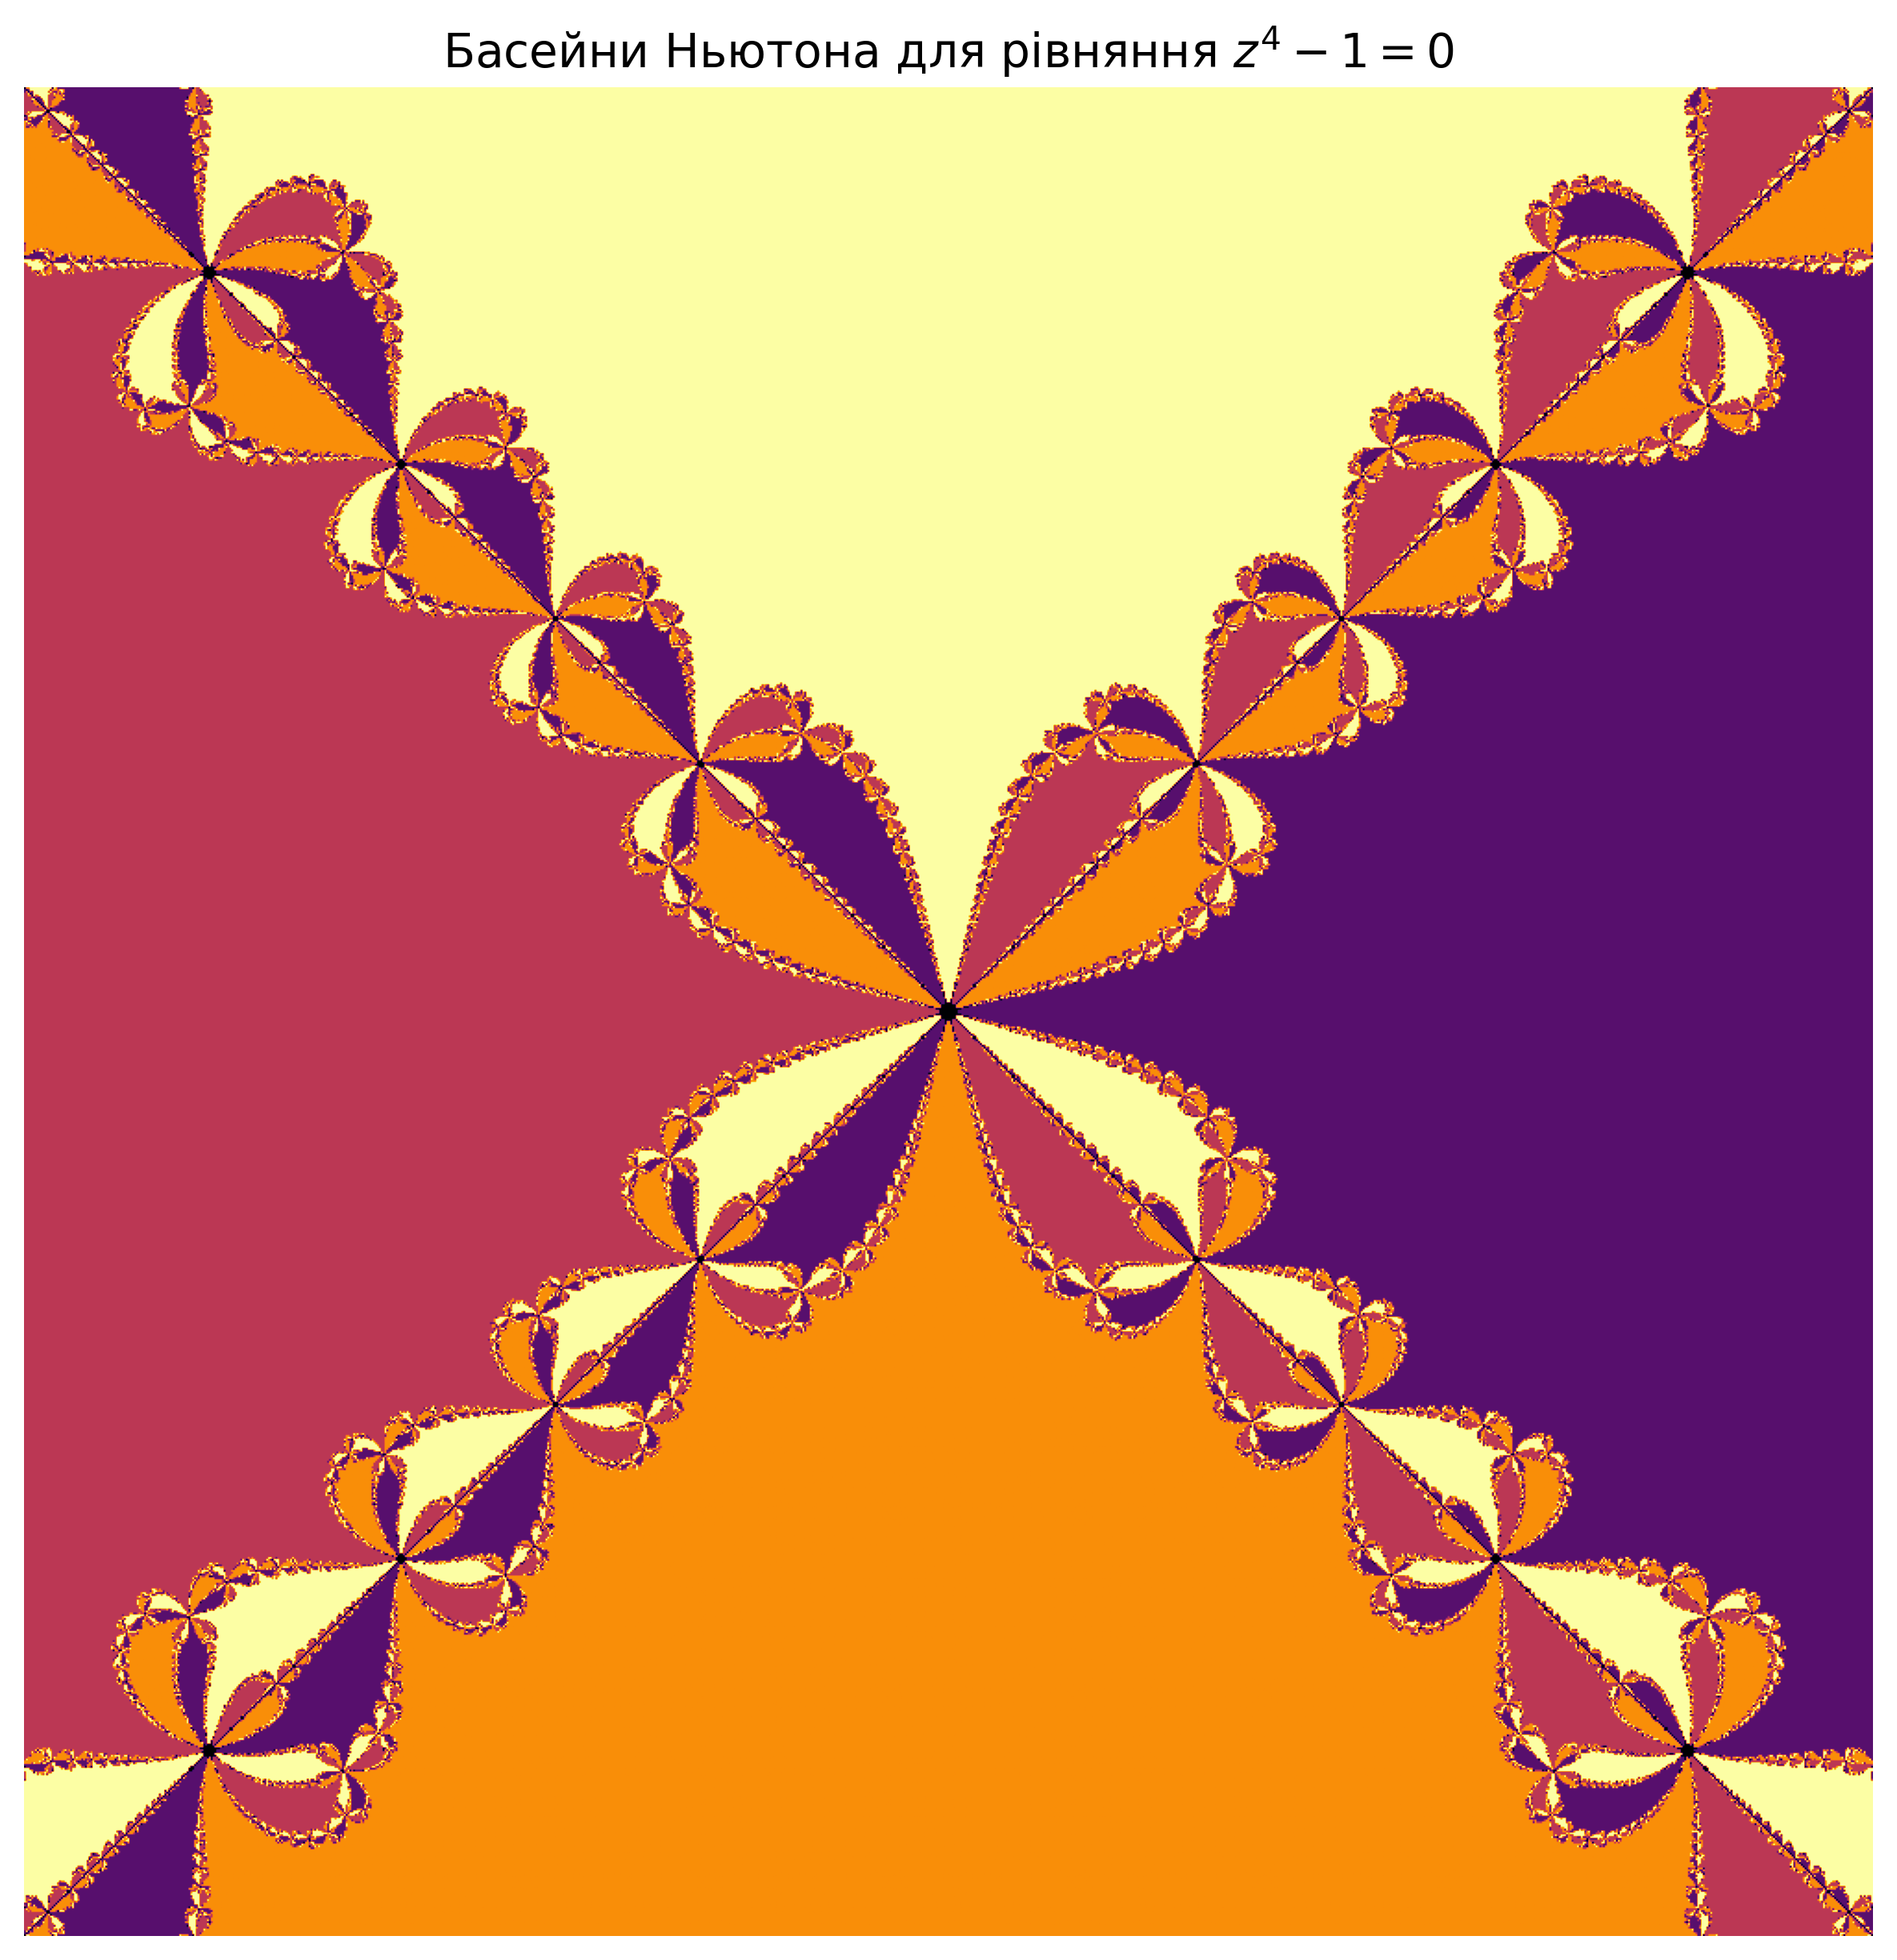

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def f(z):
    return z**4 - 1

def df(z):
    return 4 * z**3

roots = [
    1.0 + 0.0j,
    -1.0 + 0.0j,
    0.0 + 1.0j,
    0.0 - 1.0j
]
img_size = 1000  
x = np.linspace(-2, 2, img_size)
y = np.linspace(-2, 2, img_size)
X, Y = np.meshgrid(x, y)
Z = X + 1j * Y

max_iter = 40
tolerance = 1e-6

grid = np.zeros(Z.shape, dtype=int)

for i in range(max_iter):
    derivative = df(Z) 
    derivative[np.abs(derivative) < 1e-12] = 1e-12
    Z = Z - f(Z) / derivative
for idx, root in enumerate(roots):
    grid[np.abs(Z - root) < tolerance] = idx + 1

plt.figure(figsize=(10, 10), dpi=300)
plt.imshow(grid, extent=[-2, 2, -2, 2], cmap='inferno')

plt.title("Басейни Ньютона для рівняння $z^4 - 1 = 0$", fontsize=14)
plt.xlabel("Re(z) — Дійсна частина", fontsize=12)
plt.ylabel("Im(z) — Уявна частина", fontsize=12)
plt.axis('off') 
plt.savefig("newton_basins_z4.png", bbox_inches='tight', dpi=300)
plt.show()